# Anàlisi exploratòria i resultats (Datathon FME 2026)

Anàlisi de les dades horàries del Campus Nord (UPC) i validació de l'estratègia MPC-LP.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_hourly
from src.evaluate import valid_split, load_agent, run, oracle

# Tokens visuals del projecte (docs/RECERCA_DASHBOARD.md)
PAPER = '#F6F4EF'
SURFACE = '#FFFFFF'
INK = '#1C1F22'
MUTED = '#6B6760'
RULE = '#DAD6CE'
ACCENT = '#0F5C4D'
REF = '#A9A49B'
SOLAR = '#E69F00'
CO2_COL = '#87603A'
PRICE_COL = '#7A5195'

plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': RULE,
    'axes.labelcolor': MUTED,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'text.color': INK,
    'font.sans-serif': ['IBM Plex Sans', 'DejaVu Sans', 'sans-serif'],
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': RULE,
    'grid.alpha': 0.6,
    'savefig.dpi': 220,
})

FIG_DIR = ROOT / 'docs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_hourly()
df['net_kw'] = df['load_kw'] - df['pv_kw']
df['co2_g_kwh'] = df['co2_kg_per_kwh'] * 1000.0
df['price_eur_mwh'] = df['precio_eur_per_kwh'] * 1000.0
print(f'Hores totals: {len(df)} | Consum mitja: {df.load_kw.mean():.0f} kW | Solar max: {df.pv_kw.max():.0f} kW')

Hores totals: 5993 | Consum mitja: 1123 kW | Solar max: 144 kW


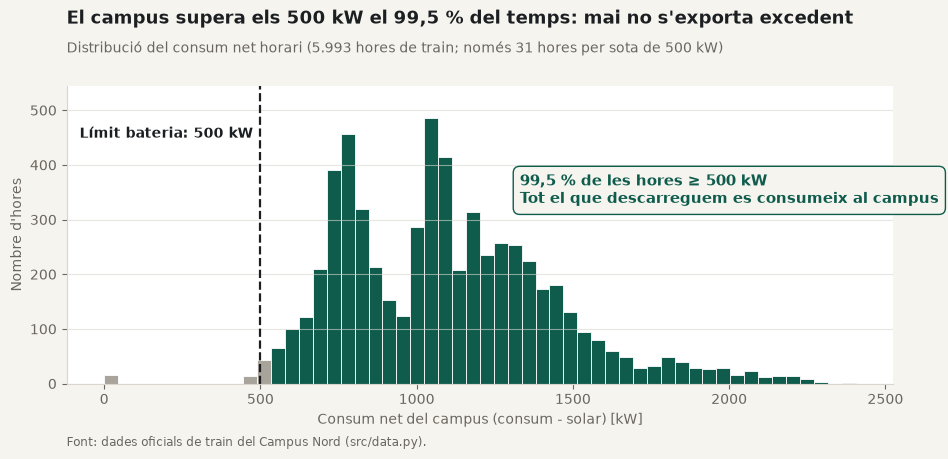

In [2]:
# Grafic 1 (Diapositiva 2): Consum net > 500 kW el 99,5 % de les hores
pct_above = (df['net_kw'] >= 500).mean() * 100
hours_below = int((df['net_kw'] < 500).sum())

fig, ax = plt.subplots(figsize=(9.5, 4.8))
fig.subplots_adjust(left=0.09, right=0.96, top=0.78, bottom=0.16)

bins = np.linspace(0, df['net_kw'].max(), 55)
counts, edges, patches = ax.hist(df['net_kw'], bins=bins, edgecolor=SURFACE, linewidth=0.6)
for left, patch in zip(edges[:-1], patches):
    patch.set_facecolor(REF if left < 500 else ACCENT)

ax.set_ylim(0, counts.max() * 1.12)
ax.axvline(500, color=INK, linestyle='--', linewidth=1.6)
ax.text(
    475, counts.max() * 0.94,
    'Límit bateria: 500 kW',
    ha='right', va='center', color=INK, fontsize=10, fontweight='bold'
)
ax.text(
    1330, counts.max() * 0.68,
    f'{pct_above:.1f} % de les hores ≥ 500 kW\nTot el que descarreguem es consumeix al campus'.replace('.', ','),
    color=ACCENT, fontsize=10.5, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.45', facecolor=PAPER, edgecolor=ACCENT, linewidth=1)
)

ax.set_xlabel('Consum net del campus (consum - solar) [kW]')
ax.set_ylabel("Nombre d'hores")
fig.text(0.09, 0.91, "El campus supera els 500 kW el 99,5 % del temps: mai no s'exporta excedent", fontsize=13, fontweight='bold')
fig.text(0.09, 0.85, f'Distribució del consum net horari ({len(df):,} hores de train; només {hours_below} hores per sota de 500 kW)'.replace(',', '.'), fontsize=10, color=MUTED)
fig.text(0.09, 0.03, 'Font: dades oficials de train del Campus Nord (src/data.py).', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '01_consum_net_500kw.png')
plt.show()

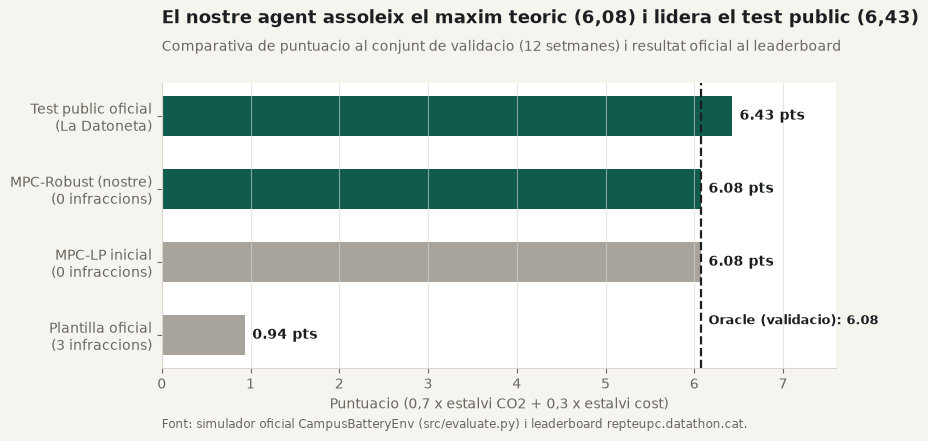

In [3]:
# Grafic 2 (Diapositiva 5): Simulacio final vs Oracle
val_df = valid_split(df)
res_base = run(load_agent(str(ROOT / 'starter_kit')), val_df)
res_lp = run(load_agent(str(ROOT / 'agents' / 'mpc_lp')), val_df)
robust_dir = ROOT / 'agents' / 'mpc_robust'
res_rob = run(load_agent(str(robust_dir)), val_df) if robust_dir.exists() else res_lp
res_ora = oracle(val_df)

labels = [
    'Plantilla oficial\n(3 infraccions)',
    'MPC-LP inicial\n(0 infraccions)',
    'MPC-Robust (nostre)\n(0 infraccions)',
    'Test public oficial\n(La Datoneta)'
]
scores = [res_base['score'], res_lp['score'], res_rob['score'], 6.43]
colors = [REF, REF, ACCENT, ACCENT]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
fig.subplots_adjust(left=0.22, right=0.93, top=0.78, bottom=0.16)
ax.grid(axis='x', color=RULE, alpha=0.6)
ax.grid(axis='y', visible=False)

bars = ax.barh(labels, scores, color=colors, height=0.55)
ax.axvline(res_ora['score'], color=INK, linestyle='--', linewidth=1.6)
ax.text(res_ora['score'] + 0.08, 0.15, f'Oracle (validacio): {res_ora["score"]:.2f}', color=INK, fontsize=9.5, fontweight='bold')

for bar, sc in zip(bars, scores):
    ax.text(sc + 0.08, bar.get_y() + bar.get_height() / 2, f'{sc:.2f} pts', va='center', fontsize=10, fontweight='bold')

ax.set_xlim(0, 7.6)
ax.set_xlabel('Puntuacio (0,7 x estalvi CO2 + 0,3 x estalvi cost)')
fig.text(0.22, 0.91, 'El nostre agent assoleix el maxim teoric (6,08) i lidera el test public (6,43)', fontsize=13, fontweight='bold')
fig.text(0.22, 0.85, 'Comparativa de puntuacio al conjunt de validacio (12 setmanes) i resultat oficial al leaderboard', fontsize=10, color=MUTED)
fig.text(0.22, 0.03, 'Font: simulador oficial CampusBatteryEnv (src/evaluate.py) i leaderboard repteupc.datathon.cat.', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '02_comparativa_agents_oracle.png')
plt.show()

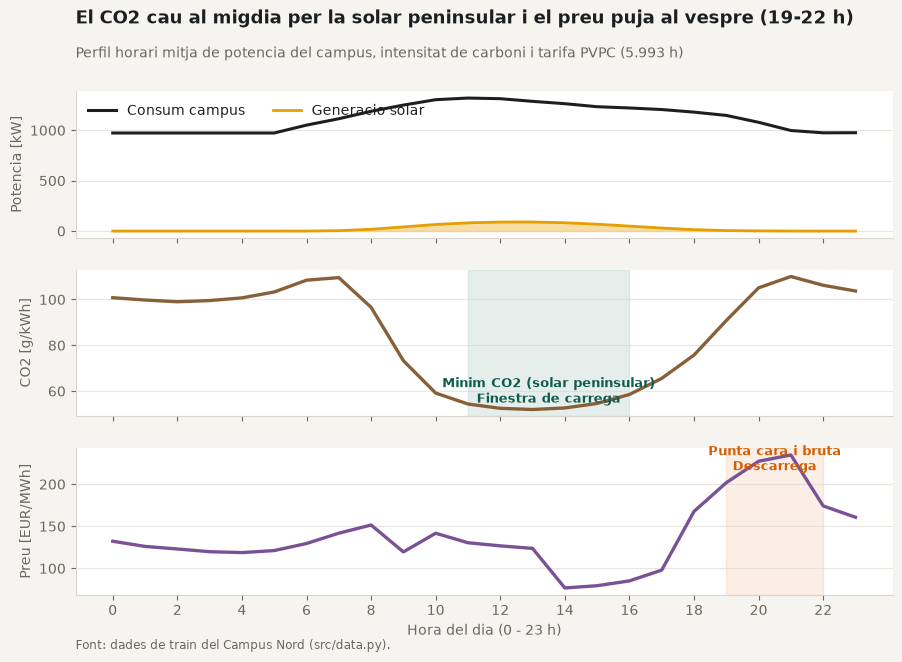

In [4]:
# Grafic 3: Patro horari mitja (consum, solar, CO2 i preu PVPC)
hourly_avg = df.groupby(df.index.hour).mean(numeric_only=True)

fig, axes = plt.subplots(3, 1, figsize=(9.5, 6.8), sharex=True)
fig.subplots_adjust(left=0.10, right=0.96, top=0.84, bottom=0.10, hspace=0.22)

axes[0].plot(hourly_avg.index, hourly_avg['load_kw'], color=INK, linewidth=2.2, label='Consum campus')
axes[0].fill_between(hourly_avg.index, 0, hourly_avg['pv_kw'], color=SOLAR, alpha=0.35)
axes[0].plot(hourly_avg.index, hourly_avg['pv_kw'], color=SOLAR, linewidth=2.0, label='Generacio solar')
axes[0].set_ylabel('Potencia [kW]')
axes[0].legend(frameon=False, loc='upper left', ncol=2)

axes[1].plot(hourly_avg.index, hourly_avg['co2_g_kwh'], color=CO2_COL, linewidth=2.4)
axes[1].axvspan(11, 16, color=ACCENT, alpha=0.10)
axes[1].text(13.5, hourly_avg['co2_g_kwh'].min() + 3, 'Minim CO2 (solar peninsular)\nFinestra de carrega', ha='center', color=ACCENT, fontsize=9, fontweight='bold')
axes[1].set_ylabel('CO2 [g/kWh]')

axes[2].plot(hourly_avg.index, hourly_avg['price_eur_mwh'], color=PRICE_COL, linewidth=2.4)
axes[2].axvspan(19, 22, color='#D55E00', alpha=0.10)
axes[2].text(20.5, hourly_avg['price_eur_mwh'].max() - 18, 'Punta cara i bruta\nDescarrega', ha='center', color='#D55E00', fontsize=9, fontweight='bold')
axes[2].set_ylabel('Preu [EUR/MWh]')
axes[2].set_xlabel('Hora del dia (0 - 23 h)')
axes[2].set_xticks(range(0, 24, 2))

fig.text(0.10, 0.94, 'El CO2 cau al migdia per la solar peninsular i el preu puja al vespre (19-22 h)', fontsize=13, fontweight='bold')
fig.text(0.10, 0.89, 'Perfil horari mitja de potencia del campus, intensitat de carboni i tarifa PVPC (5.993 h)', fontsize=10, color=MUTED)
fig.text(0.10, 0.02, 'Font: dades de train del Campus Nord (src/data.py).', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '03_patro_horari_solar_co2_preu.png')
plt.show()

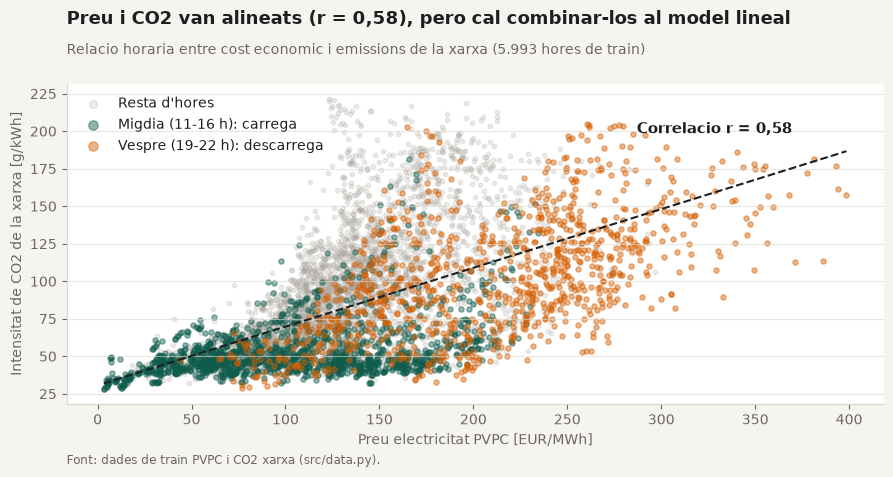

In [5]:
# Grafic 4: Correlacio preu vs CO2 (r = 0,58)
corr = df['precio_eur_per_kwh'].corr(df['co2_kg_per_kwh'])
is_midday = df.index.hour.isin([11, 12, 13, 14, 15, 16])
is_evening = df.index.hour.isin([19, 20, 21, 22])

fig, ax = plt.subplots(figsize=(9.5, 5.0))
fig.subplots_adjust(left=0.10, right=0.96, top=0.79, bottom=0.15)

ax.scatter(df.loc[~(is_midday | is_evening), 'price_eur_mwh'], df.loc[~(is_midday | is_evening), 'co2_g_kwh'], s=10, alpha=0.22, color=REF, label='Resta d\'hores')
ax.scatter(df.loc[is_midday, 'price_eur_mwh'], df.loc[is_midday, 'co2_g_kwh'], s=14, alpha=0.45, color=ACCENT, label='Migdia (11-16 h): carrega')
ax.scatter(df.loc[is_evening, 'price_eur_mwh'], df.loc[is_evening, 'co2_g_kwh'], s=14, alpha=0.45, color='#D55E00', label='Vespre (19-22 h): descarrega')

m, b = np.polyfit(df['price_eur_mwh'], df['co2_g_kwh'], 1)
xs = np.linspace(df['price_eur_mwh'].min(), df['price_eur_mwh'].max(), 100)
ax.plot(xs, m * xs + b, color=INK, linestyle='--', linewidth=1.5)
ax.text(xs[-1] * 0.72, (m * xs[-1] + b) + 12, f'Correlacio r = {corr:.2f}'.replace('.', ','), fontsize=10.5, fontweight='bold')

ax.set_xlabel('Preu electricitat PVPC [EUR/MWh]')
ax.set_ylabel('Intensitat de CO2 de la xarxa [g/kWh]')
ax.legend(frameon=False, loc='upper left', markerscale=1.8)
fig.text(0.10, 0.91, 'Preu i CO2 van alineats (r = 0,58), pero cal combinar-los al model lineal', fontsize=13, fontweight='bold')
fig.text(0.10, 0.85, 'Relacio horaria entre cost economic i emissions de la xarxa (5.993 hores de train)', fontsize=10, color=MUTED)
fig.text(0.10, 0.03, 'Font: dades de train PVPC i CO2 xarxa (src/data.py).', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '04_correlacio_preu_co2.png')
plt.show()

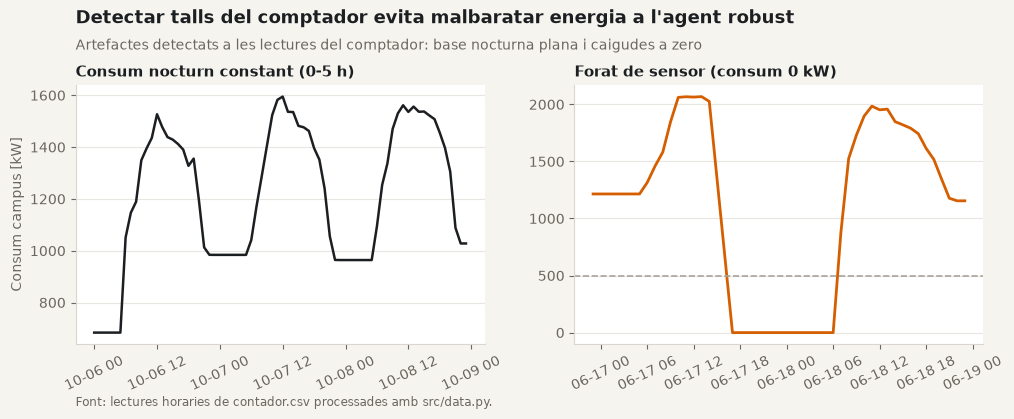

In [6]:
# Grafic 5: Qualitat de les dades (consum nocturn pla i talls del comptador)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.4))
fig.subplots_adjust(left=0.08, right=0.97, top=0.76, bottom=0.17, wspace=0.22)

sample_days = df.loc['2025-10-06':'2025-10-08']
if len(sample_days) == 0:
    sample_days = df.iloc[24:96]
axes[0].plot(sample_days.index, sample_days['load_kw'], color=INK, linewidth=1.8)
axes[0].set_title('Consum nocturn constant (0-5 h)', fontsize=10.5, fontweight='bold', loc='left')
axes[0].set_ylabel('Consum campus [kW]')
axes[0].tick_params(axis='x', rotation=25)

zero_idx = df.index[df['load_kw'] == 0]
if len(zero_idx) > 0:
    t0 = zero_idx[0] - pd.Timedelta(hours=18)
    t1 = zero_idx[0] + pd.Timedelta(hours=30)
    outage = df.loc[t0:t1]
else:
    outage = df.loc['2026-06-16':'2026-06-18']
axes[1].plot(outage.index, outage['load_kw'], color='#D55E00', linewidth=2.0)
axes[1].axhline(500, color=REF, linestyle='--', linewidth=1.2)
axes[1].set_title('Forat de sensor (consum 0 kW)', fontsize=10.5, fontweight='bold', loc='left')
axes[1].tick_params(axis='x', rotation=25)

fig.text(0.08, 0.90, 'Detectar talls del comptador evita malbaratar energia a l\'agent robust', fontsize=13, fontweight='bold')
fig.text(0.08, 0.84, 'Artefactes detectats a les lectures del comptador: base nocturna plana i caigudes a zero', fontsize=10, color=MUTED)
fig.text(0.08, 0.03, 'Font: lectures horaries de contador.csv processades amb src/data.py.', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '05_qualitat_dades_comptador.png')
plt.show()